# Проект. Исследование стартапов

Хромов Денис. 29.06.2026

## Введение

Финансовая компания, работающая с венчурными инвестициями, хочет понять закономерности финансирования стартапов и оценить перспективы выхода на рынок с покупкой и развитием компаний. Для этого необходимо провести исследование на исторических данных. Вы поработаете с информацией о компаниях, объёмах и типах привлечённых инвестиций, а также с дополнительной статистикой по возвратам средств.


Цель: Подготовить датасет к работе, исследовать динамику и структуру финансирования стартапов и ответить на вопросы, важные для оценки инвестиционных стратегий.

Задачи:

- Провести предобработку данных, убрать дубликаты и пропуски, проверить корректность числовых и временных значений.
- Выделить группы компаний по срокам финансирования и сравнить их по количеству и объёму инвестиций.
- Классифицировать сегменты рынка на массовые, средние и нишевые и учесть это в дальнейшем анализе.
- Определить типичные и аномальные значения объёмов финансирования, исключить выбросы и ограничить период исследования.
- Сравнить популярность и объёмы разных типов финансирования.
- Проанализировать динамику раундов и объёмов инвестиций по годам, а также изменения в массовых сегментах рынка.
- Рассчитать долю возврата средств для разных типов финансирования и оценить её устойчивость.
- Подвести итоговые выводы и дать рекомендации, куда и каким образом было бы целесообразно инвестировать, если бы на дворе был 2015 год.

На основе полученных результатов дать рекомендации по инвестиционной стратегии на 2015 год, указав приоритетные типы финансирования и рыночные сегменты.

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

Файлы находятся в папке `datasets`, если вы выполняете работу на платформе. В случае, если вы делаете работу локально, доступ к файлам в папке можно получить по адресу `https://code.s3.yandex.net/datasets/` + имя файла.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install phik==0.11.0

     |████████████████████████████████| 594 kB 1.5 MB/s eta 0:00:01
  Created wheel for phik: filename=phik-0.11.0-py3-none-any.whl size=599734 sha256=85ff4366cf3e193915b7c6dcaac1b5778e4586c330764468279f6236d16a09fa
  Stored in directory: /home/jovyan/.cache/pip/wheels/f4/62/e1/886fe092e3a53f783898861c58016ca757fcd0523db7c2cefe
Successfully built phik


In [3]:
df_investments = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)
df_returns = pd.read_csv("https://code.s3.yandex.net/datasets/cb_returns.csv")

Осмотрим оба датасета

In [4]:
df_investments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [5]:
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


In [6]:
df_investments.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
df_returns.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


Сделайте вывод о полученных данных: каков их объём, соответствуют ли данные описанию, есть ли пропущенные значения, используются ли верные типы данных. Отметьте другие особенности данных, которые вы обнаружите на этой стадии и на которые стоит обратить внимание при предобработке.

В датафрейме investments общее кол-во строк: 54 294 строк и столбцов: 40
Пропущенные значения присутствуют в каждом столбце датасета. Причем во многих столбцах одинаковое количество non null значений, так что в дальнейшем нужно проверить на полностью пустые строки  

В некоторых столбцах неверно определены типы данных, которые в дальнейшем нужно изменить

В датафреймеreturns кол-во строк: 15 и столбцов: 14  
В нем ошибок к исправлению замечено не было

### 1.2. Предобработка данных

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведите их к единому аккуратному стилю.

In [8]:
df_investments.columns

Index(['name', 'homepage_url', 'category_list', ' market ',
       ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region',
       'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

In [9]:
df_returns.columns

Index(['year', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
       'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding'],
      dtype='object')

В названиях столбцов датафрейма investments существуют пробелы перед и после кавычек. 

Также приведем столбцы с round_... к snake case

In [10]:
df_investments.columns = df_investments.columns.str.strip()
df_investments.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

In [11]:
# Список столбцов, которые нужно переименовать
columns_to_rename = ['round_A', 'round_B', 'round_C', 'round_D',
                      'round_E', 'round_F', 'round_G', 'round_H']

rename_dict = {col: col.lower() for col in columns_to_rename}

df_investments = df_investments.rename(columns=rename_dict)
df_investments.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_a', 'round_b',
       'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h'],
      dtype='object')

In [12]:
#Проверим наличие полностью пустых строк
rows_before_changes = df_investments.shape[0]
df_investments.isna().all(axis=1).sum()

4856

In [13]:
#Удалим их т.к. они не содержат в себе никакой информации  
df_investments = df_investments.dropna(how='all')

Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [14]:
# Заменяем строки, состоящие только из дефиса и пробелов, на NaN
df_investments['funding_total_usd'] = df_investments['funding_total_usd'].replace(r'^\s*-\s*$', np.nan, regex=True)

# Убираем запятые и пробелы, преобразуем в float
df_investments['funding_total_usd'] = (
    df_investments['funding_total_usd']
    .str.replace(',', '', regex=False)  
    .str.strip()                       
    .astype(float)                     
)


df_investments['funding_total_usd'].head

<bound method NDFrame.head of 0        90000000.0
1         2000000.0
2         9000000.0
3         7700000.0
4          540000.0
            ...    
49433     1500000.0
49434     9000000.0
49435      250000.0
49436    34000000.0
49437       11500.0
Name: funding_total_usd, Length: 49438, dtype: float64>

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

Столбцы founded_at, founded_month, founded_quarter, founded_year, first_funding_at, mid_funding_at и last_funding_at имеют неверные типы данных, однако столбцы отображающие только месяц, год и квартал - мы можем оставить как есть, изменив только типы столбцов предполагающие отображение полной даты

In [15]:
df_investments['founded_at'].head

<bound method NDFrame.head of 0        1636-09-08
1        1785-01-01
2        1802-07-19
3        1817-01-01
4        1826-01-01
            ...    
49433           NaN
49434           NaN
49435           NaN
49436           NaN
49437           NaN
Name: founded_at, Length: 49438, dtype: object>

In [16]:
df_investments['last_funding_at'].head

<bound method NDFrame.head of 0        2014-01-06
1        2014-05-15
2        2009-07-02
3        2014-11-03
4        2014-01-14
            ...    
49433    2014-12-01
49434    2014-12-01
49435    2014-12-02
49436    2014-12-02
49437    2014-12-31
Name: last_funding_at, Length: 49438, dtype: object>

In [17]:
df_investments['mid_funding_at'].head

<bound method NDFrame.head of 0               NaN
1               NaN
2        2009-07-02
3        2013-11-21
4               NaN
            ...    
49433           NaN
49434           NaN
49435           NaN
49436           NaN
49437           NaN
Name: mid_funding_at, Length: 49438, dtype: object>

In [18]:
df_investments['first_funding_at'].head

<bound method NDFrame.head of 0        2014-01-06
1        2014-05-15
2        2009-07-02
3        2013-11-21
4        2014-01-14
            ...    
49433    2014-12-01
49434    2014-12-01
49435    2014-12-02
49436    2014-12-02
49437    2014-12-31
Name: first_funding_at, Length: 49438, dtype: object>

In [19]:
df_investments['founded_at'] = pd.to_datetime(df_investments['founded_at'], errors='coerce')
df_investments['first_funding_at'] = pd.to_datetime(df_investments['first_funding_at'], errors='coerce')
df_investments['mid_funding_at'] = pd.to_datetime(df_investments['mid_funding_at'], errors='coerce')
df_investments['last_funding_at'] = pd.to_datetime(df_investments['last_funding_at'], errors='coerce')

In [20]:
df_investments.dtypes

name                            object
homepage_url                    object
category_list                   object
market                          object
funding_total_usd              float64
status                          object
country_code                    object
state_code                      object
region                          object
city                            object
funding_rounds                 float64
participants                   float64
founded_at              datetime64[ns]
founded_month                   object
founded_quarter                 object
founded_year                   float64
first_funding_at        datetime64[ns]
mid_funding_at          datetime64[ns]
last_funding_at         datetime64[ns]
seed                           float64
venture                        float64
equity_crowdfunding            float64
undisclosed                    float64
convertible_note               float64
debt_financing                 float64
angel                    

В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [21]:
df_returns = df_returns.set_index('year')
df_returns.head()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [22]:
missing_counts = df_investments.isnull().sum()
print(missing_counts[missing_counts > 0])


name                     1
homepage_url          3449
category_list         3961
market                3961
funding_total_usd     8531
status                1314
country_code          5273
state_code           19277
region                5273
city                  6116
participants         18965
founded_at           10885
founded_month        10956
founded_quarter      10956
founded_year         10884
first_funding_at        10
mid_funding_at       19150
last_funding_at          6
dtype: int64


In [23]:
text_columns = ['name','homepage_url','category_list','market','status','country_code','state_code','region','city']
df_investments[text_columns] = df_investments[text_columns].fillna('не указано')
missing_counts = df_investments.isnull().sum()
print(missing_counts[missing_counts > 0])

funding_total_usd     8531
participants         18965
founded_at           10885
founded_month        10956
founded_quarter      10956
founded_year         10884
first_funding_at        10
mid_funding_at       19150
last_funding_at          6
dtype: int64


Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [24]:
df_investments = df_investments.drop_duplicates()
df_investments = df_investments[df_investments['funding_total_usd'].notna()]
df_investments = df_investments.dropna(how='all')

Заполните пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмите приблизительно середину интервала между этими двумя датами.

Оцените размер оставшихся пропусков в столбце.

In [25]:
df_investments['mid_funding_at'].isna().sum() / df_investments.shape[0] * 100

33.43193096536045

In [26]:
mid_values = df_investments['first_funding_at'] + (df_investments['last_funding_at'] - df_investments['first_funding_at']) / 2
df_investments['mid_funding_at'] = df_investments['mid_funding_at'].fillna(mid_values)


In [27]:
df_investments['mid_funding_at'].isna().sum() / df_investments.shape[0] * 100

0.0024445693891021096

Количество пропусков теперь составляет меньше 1%

Оцените полноту данных и сделайте предварительный вывод о том, достаточно ли данных для решения задач проекта. Какой процент данных был отброшен?

In [28]:
processed_data = df_investments.shape[0]  # количество строк после обработки
rows_removed = rows_before_changes - processed_data  # сколько строк удалено
droped = (rows_removed / rows_before_changes) * 100  # процент удалённых строк

droped, processed_data

(24.656499797399345, 40907)

В результате обработки данных:

- Удалены 4 856 полностью пустых строк, не содержащих информации.
- Из названий столбцов убраны лишние пробелы и прочие знаки, все столбцы приведены к единому стилю написания
- Столбцы с целыми датами приведены к формату datetime64.
- Столбец funding_total_usd преобразован из object с разделителями разрядов в числовой тип.
- Сделали столбец year индексом всего датасета.
- Пропуски в текстовых и вспомогательных столбцах заменены на заглушку.  
- Пропуски в mid_funding_at (39%) заполнены серединным значением и сокращена доля пропусков до 0.0002%  

- Всего удалено 24,7% записей, данные обработаны от пропусков и дубликатов и предоставлены в чистом виде для дальнейшего анализа


In [29]:
df_investments['market'].value_counts()

 Software                     4190
 Biotechnology                3531
не указано                    2503
 Mobile                       1852
 E-Commerce                   1528
                              ... 
 Online Video Advertising        1
Digital Entertainment            1
 Bicycles                        1
 Video                           1
 3D                              1
Name: market, Length: 849, dtype: int64

In [30]:
df_investments['market'] = df_investments['market'].str.strip()

## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.



In [31]:
def classify_funding(row):
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    elif pd.notna(row['first_funding_at']) and pd.notna(row['last_funding_at']):
        days = (row['last_funding_at'] - row['first_funding_at']).days
        return 'Срок финансирования до года' if days <= 365 else 'Срок финансирования более года'

df_investments['funding_group'] = df_investments.apply(classify_funding, axis=1)

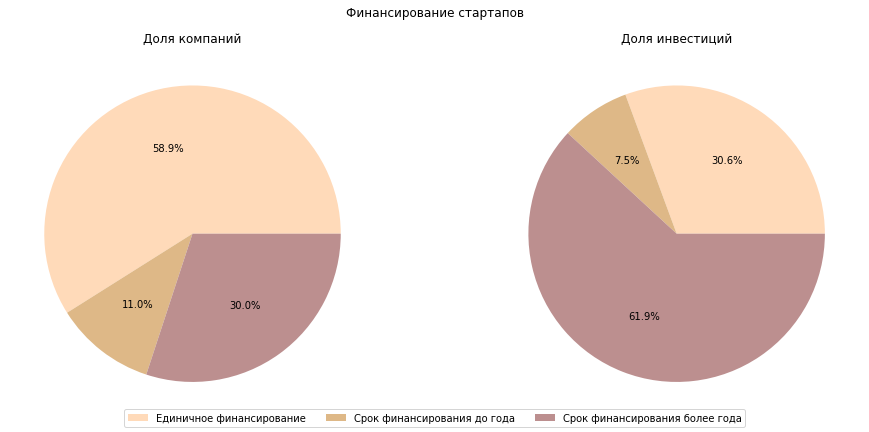

In [32]:

# Собираем статистику: количество компаний и сумма инвестиций по группам
group_counts = df_investments['funding_group'].value_counts()
group_investments = df_investments.groupby('funding_group')['funding_total_usd'].sum()

# Единая цветовая палитра
colors = {
    'Единичное финансирование': 'peachpuff',
    'Срок финансирования до года': 'burlywood',
    'Срок финансирования более года': 'rosybrown'
}

# Задаём порядок групп — это важно для единообразия
groups_order = ['Единичное финансирование', 'Срок финансирования до года', 'Срок финансирования более года']

# Создаём DataFrame с явным порядком групп и заполняем отсутствующие значения нулями
data = pd.DataFrame({
    'Количество компаний': group_counts,
    'Сумма инвестиций (USD)': group_investments
}).reindex(groups_order, fill_value=0)

# Получаем цвета в том же порядке
colors_ordered = [colors[group] for group in groups_order]

# Настройка фигуры
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# График по количеству компаний
ax1.pie(data['Количество компаний'], colors=colors_ordered, autopct='%1.1f%%')
ax1.set_title('Доля компаний')

# График по сумме инвестиций
ax2.pie(data['Сумма инвестиций (USD)'], colors=colors_ordered, autopct='%1.1f%%')
ax2.set_title('Доля инвестиций')

# Общая легенда для обоих графиков
fig.legend(groups_order, loc='lower center', ncol=3)
plt.suptitle('Финансирование стартапов')
plt.tight_layout()
plt.show()


Большая часть кампаний финансируется единожды, однако доля инвестиций составляет почти треть от всех.  
 - Вывода может быть два - либо это "стрельнувшие" кампании, не нуждающиеся более в инвестициях извне, либо напротив кампании, не оправдавшие ожиданий инвесторов(Нужно детальнее изучить конкретные кейсы, чтобы сказать точно)  
 
Наименьшее количество кампаний - со сроком финансирования до года соответственно, как и доля финансирования на них.  

Наибольшая же доля инвестиций приходится на долгосрочные кампании с дальнейшими перспективами.
 - Можно предположить, что инвесторам проще продать прорпботанный план долгосрочного вложения и выхлопа от него, чем единичные и краткосрочные проекты

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

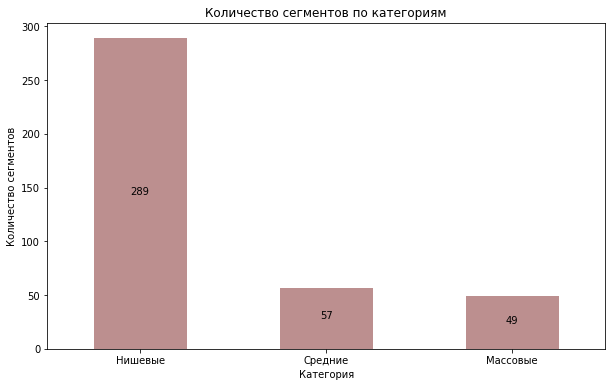

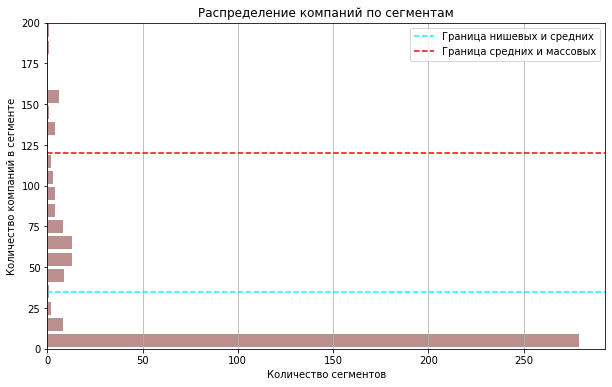

In [33]:
market_counts = df_investments['market'].dropna().value_counts()
segments = pd.cut(market_counts, bins=[0, 35, 120, 9999999], labels=['Нишевые', 'Средние', 'Массовые'], right=True)

segment_sum = segments.value_counts().sort_index()

segment_sum.plot(
    kind='bar',
    title='Количество сегментов по категориям',
    ylabel='Количество сегментов',
    xlabel='Категория',
    rot=0,
    color = 'rosybrown',
    figsize=(10, 6)
)

for i, v in enumerate(segment_sum):
        plt.text(i, v // 2, v, ha='center')
plt.show() 

# Считаем, количество сегментов на диапазон
bins = range(0, int(market_counts.max()) + 10, 10)
counts, bin_edges = np.histogram(market_counts, bins=bins)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

plt.figure(figsize=(10, 6))

# Строим диаграмму
bars = plt.barh(bin_centers, counts, color='rosybrown', height=8)

# Определяем границы сегментов
plt.axhline(35, linestyle='--', label='Граница нишевых и средних', color='aqua')
plt.axhline(120, linestyle='--', label='Граница средних и массовых', color='red')

# Подписываем график и оси
plt.title('Распределение компаний по сегментам')
plt.xlabel('Количество сегментов')
plt.ylabel('Количество компаний в сегменте')

plt.ylim(0, 200)

plt.legend()
plt.grid(axis='x')  

plt.show()


Большая часть компаний приходится на нишевый сегмент, тогда как массовых - совсем малая часть

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


In [34]:
def categorize_market(row):
    # Берём уже преобразованное значение из столбца
    mapped_value = row['market_mapped']  # предполагаем, что столбец уже создан

    if mapped_value == 'Нишевые':
        return 'niche'
    elif mapped_value == 'Средние':
        return 'mid'
    elif mapped_value == 'Массовые':
        return row['market']  # исходное название рынка
    else:
        return mapped_value

# Сначала создаём маппинговый столбец
df_investments['market_mapped'] = df_investments['market'].map(segments)

# Затем применяем функцию
df_investments['market_group'] = df_investments.apply(categorize_market, axis=1)

# Можно удалить временный столбец, если он не нужен
df_investments = df_investments.drop('market_mapped', axis=1)
df_investments['market_group']

0         Education
1        не указано
2               mid
3         Education
4         Education
            ...    
49433    не указано
49434         niche
49435    не указано
49436    не указано
49437      Startups
Name: market_group, Length: 40907, dtype: object

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

<Figure size 864x432 with 0 Axes>

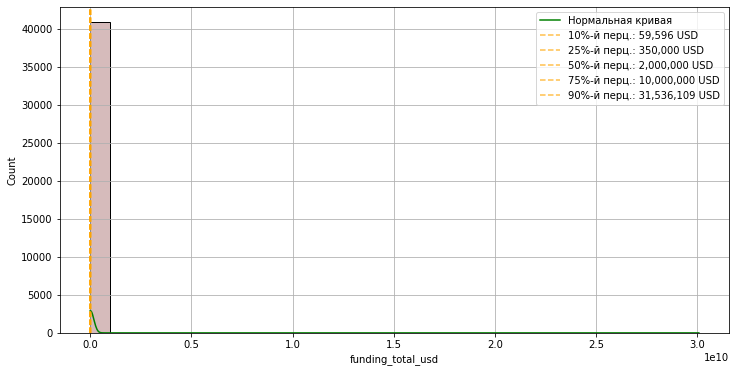

In [35]:
# Вычисляем показатели
percentiles = [10, 25, 50, 75, 90]
labels = [f'{p}%-й перц.: {np.percentile(df_investments["funding_total_usd"], p):,.0f} USD' for p in percentiles]
mean = df_investments['funding_total_usd'].mean()
std = df_investments['funding_total_usd'].std()
median = df_investments['funding_total_usd'].median()  # Вычисляем медиану

x = np.linspace(df_investments['funding_total_usd'].min(),
                df_investments['funding_total_usd'].max(), 1000)
pdf = (1/(std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mean) / std) ** 2)

plt.figure(figsize=(12, 6))
# Строим гистограмму
plt.figure(figsize=(12, 6))
sns.histplot(df_investments['funding_total_usd'], bins=30, kde=False,
             color='rosybrown', stat='count', alpha=0.6)
plt.plot(x, pdf * (df_investments.shape[0] * (x[1] - x[0])),
         color='green', label='Нормальная кривая')

# Добавляем линии для процентилей
for p, label in zip(percentiles, labels):
    plt.axvline(np.percentile(df_investments['funding_total_usd'], p),
                color='orange', linestyle='--', alpha=0.7, label=label)

plt.legend()
plt.grid(True)
plt.show()


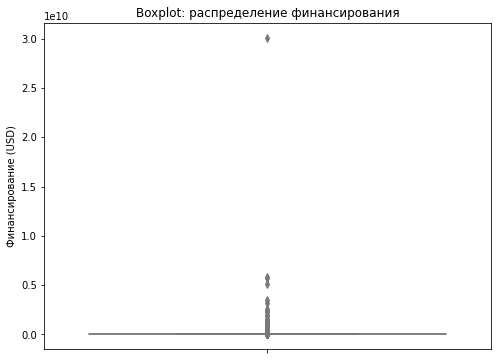

In [36]:
plt.figure(figsize=(8, 6))
sns.boxplot(y=df_investments['funding_total_usd'], color='lightblue')
plt.title('Boxplot: распределение финансирования')
plt.ylabel('Финансирование (USD)')
plt.show()


Мы видим, что медиана составляет 2млн, где и расположилось большее кол-во компаний.  
Большая часть компаний находится в диапазоне до 10млн. А все, что находится выше значения 32млн - выбросы

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

In [37]:
# Рассчитываем квартили по группам
Q1 = df_investments.groupby('market_group')['funding_total_usd'].transform('quantile', 0.25)
Q3 = df_investments.groupby('market_group')['funding_total_usd'].transform('quantile', 0.75)
IQR = Q3 - Q1

# Определяем границы
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Помечаем выбросы
df_investments['is_outlier'] = (df_investments['funding_total_usd'] < lower_bound) | (df_investments['funding_total_usd'] > upper_bound)

# Получаем аномалии
anomalies = df_investments[df_investments['is_outlier']]
anomalies[['name', 'market_group', 'funding_total_usd']].head(10)


,name,market_group,funding_total_usd
0,Harvard University,Education,90000000.0
5,Xavier University,не указано,19000000.0
6,Tulane University,Education,12000000.0
8,"Virginia Commonwealth University, Richmond",не указано,6000000.0
10,VideoSurf,Hardware + Software,28000000.0
14,University of Florida,не указано,8000000.0
17,University of Maryland,Education,750500000.0
20,Great Atlantic & Pacific Tea,Hospitality,175000000.0
23,Massachusetts Institute of Technology - MIT,Education,90000000.0
30,University of Maine,Education,30800000.0


Определяем Топ-10

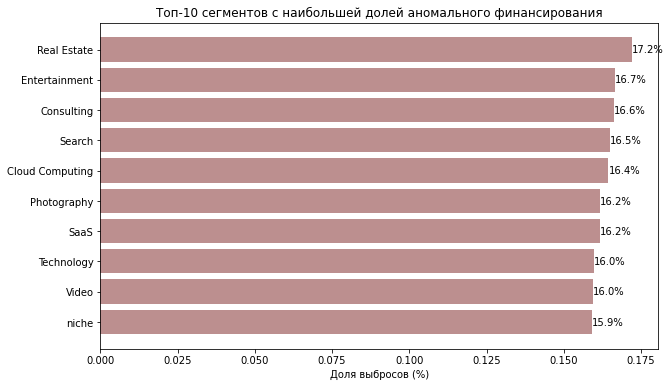

In [38]:
# Считаем общее количество записей по группам
total_counts = df_investments['market_group'].value_counts().reset_index()
total_counts.columns = ['market_group', 'total']

# Считаем количество выбросов по группам
outlier_counts = (df_investments[df_investments['is_outlier'] == 1]
                  ['market_group']
                  .value_counts()
                  .reset_index())
outlier_counts.columns = ['market_group', 'outliers']

# Объединяем данные
stats = total_counts.merge(outlier_counts, on='market_group', how='left').fillna(0)
stats['ratio'] = stats['outliers'] / stats['total']
top_10_segments = stats.sort_values('ratio', ascending=False).head(10)

# Строим диаграмму
plt.figure(figsize=(10, 6))
bars = plt.barh(top_10_segments['market_group'], top_10_segments['ratio'], color='rosybrown')
plt.xlabel('Доля выбросов (%)')
plt.title('Топ‑10 сегментов с наибольшей долей аномального финансирования')
plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()
    y_pos = bar.get_y() + bar.get_height() / 2
    plt.text(width, y_pos, f'{width * 100:.1f}%', va='center')

plt.show()



Лидирующюю строчку по аномалиям занимает рынок недвижимости, в остальных сегментах значения имеют небольшой разброс, что логично, т.к. рынок недвижимости является одним из самых капитализированных сегментов в принципе, и к тому же достаточно стабильным 

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [39]:
df_investments['last_year'] = df_investments['last_funding_at'].dt.year


 
# Убедимся что в заданном году присутствуют записи по всем месяцам
funding_2014 = df_investments[df_investments['last_funding_at'].dt.year == 2014]

sorted(funding_2014['last_funding_at'].dt.month.unique())

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

In [40]:
funding_2014 = df_investments[df_investments['last_funding_at'].dt.year == 2014]
months_2014 = sorted(funding_2014['last_funding_at'].dt.month.unique())

all_months = list(range(1, 13))
missing_months = [m for m in all_months if m not in months_2014] 

monthly_counts = funding_2014['last_funding_at'].dt.month.value_counts().sort_index()
print("Количество записей по месяцам за 2014 год:")
print(monthly_counts)
print(f"Найденные месяцы в данных за 2014 год: {months_2014}")
print(f"Всего уникальных месяцев: {len(months_2014)}")
print(len(funding_2014))

Количество записей по месяцам за 2014 год:
1     1178
2      947
3     1072
4     1077
5     1036
6     1229
7     1254
8     1064
9     1135
10    1139
11     732
12      52
Name: last_funding_at, dtype: int64
Найденные месяцы в данных за 2014 год: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Всего уникальных месяцев: 12
11915


In [41]:
print(f"Найденные месяцы в данных за 2014 год: {months_2014}")
print(f"Всего уникальных месяцев: {len(months_2014)}")



Найденные месяцы в данных за 2014 год: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Всего уникальных месяцев: 12


Исключим компании имеющие аномальные значения финансирования

In [42]:
rows_before_changes = df_investments.shape[0]

df_investments = df_investments.loc[~df_investments['is_outlier']]

rows_after_anomalies = df_investments.shape[0]
rows_before_changes, rows_after_anomalies

(40907, 35663)

Мы исключили 5202 строки

На основе столбцов mid_funding_at и funding_rounds оставим в датасете данные только об определённых компаниях.

In [43]:
df_investments['mid_year'] = df_investments['mid_funding_at'].dt.year
rounds = df_investments.groupby('mid_year')['funding_rounds'].sum()
active_years_set = set(rounds[rounds >= 50].index)

# Фильтруем по условию
df_investments = df_investments.loc[df_investments['mid_year'].isin(active_years_set)]

rows_after_rounds = df_investments.shape[0]
rows_after_anomalies, rows_after_rounds


(35663, 35588)

### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

In [44]:
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 
    'convertible_note', 'debt_financing', 'angel', 'grant',
    'private_equity', 'post_ipo_equity', 'post_ipo_debt',
    'secondary_market', 'product_crowdfunding']

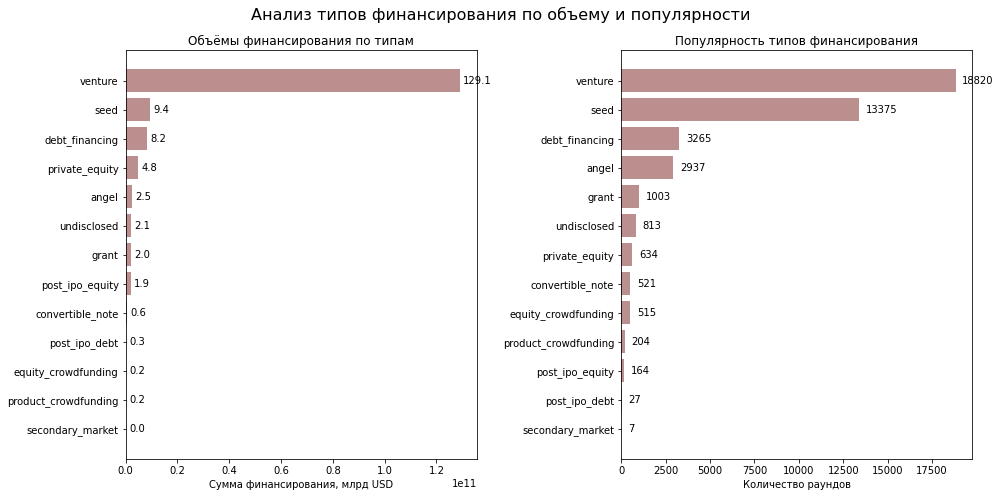

In [45]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# Первый график: объёмы финансирования по типам
total_type = df_investments[funding_types].sum().sort_values(ascending=True)

# Строим горизонтальные столбцы с заданным цветом
bars1 = ax1.barh(
    total_type.index,
    total_type.values,
    color='rosybrown'  
)
ax1.set_title('Объёмы финансирования по типам')
ax1.set_xlabel('Сумма финансирования, млрд USD')

for bar in bars1:
    width = bar.get_width()
    ax1.text(
        width + total_type.max() * 0.01,  
        bar.get_y() + bar.get_height() / 2,
        f'{width / 1e9:.1f}',  
        ha='left',
        va='center',
        fontsize=10
    )

# Второй график: популярность типов финансирования
count_types = (df_investments[funding_types] > 0).sum().sort_values(ascending=True)

bars2 = ax2.barh(
    count_types.index,
    count_types.values,
    color='rosybrown'  
)
ax2.set_title('Популярность типов финансирования')
ax2.set_xlabel('Количество раундов')

# Добавляем текстовые метки с количеством
for bar in bars2:
    width = bar.get_width()
    ax2.text(
        width + count_types.max() * 0.02,  
        bar.get_y() + bar.get_height() / 2,
        f'{int(width)}',
        ha='left',
        va='center',
        fontsize=10
    )

plt.suptitle('Анализ типов финансирования по объему и популярности', fontsize=16)
plt.tight_layout()
plt.show()


Венчурное финансирование лидирует с большим отрывом, капитализация которого составляет 128.8 млрд.  
Также в топ-3 попали seed, debt_financing и angel, однако сумма финансирования невелика, хотя и держится на первых местах по объему

Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

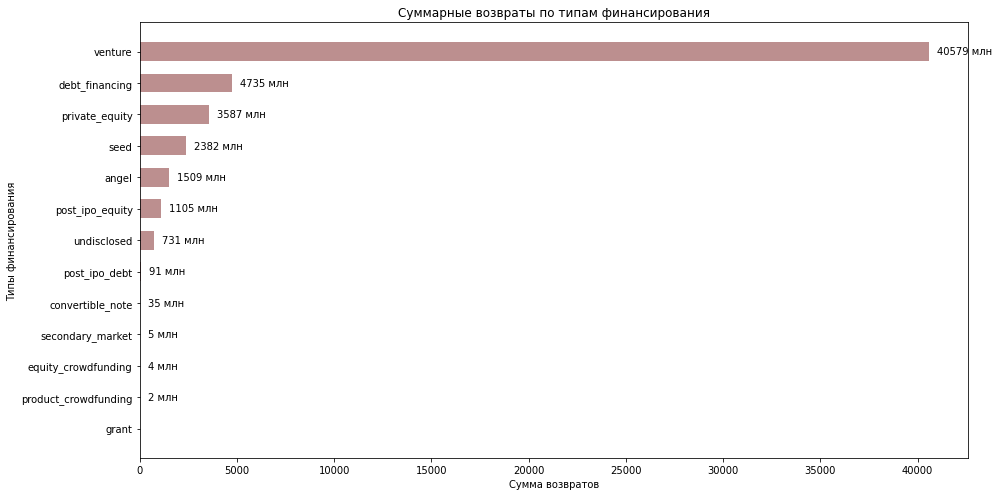

In [46]:
total_returns = df_returns[funding_types].sum().sort_values(ascending=True)

plt.figure(figsize=(14, 7))
bars = plt.barh(
    total_returns.index,          
    total_returns.values,         
    color='rosybrown',          
    height=0.6                  
)

plt.xlabel('Сумма возвратов')
plt.ylabel('Типы финансирования')
plt.title('Суммарные возвраты по типам финансирования')

# Добавляем подписи к столбцам
for bar in bars:
    width = bar.get_width()
    if width > 0:
        plt.text(
            width + max(total_returns.values) * 0.01,  
            bar.get_y() + bar.get_height() / 2,       
            f'{width:.0f} млн',
            ha='left',           
            va='center'         
        )

plt.tight_layout()
plt.show()


Венчурное финансирование - абсолютный лидер в суммарных возвратах среди других типов и имеет отрыв от 2-го емста почти в 9 раз. 
Тогда как гранты и краудфандинг имеют самую низкую сумму возвратов среди остальных

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

In [47]:
df_investments['avg_usd'] = df_investments['funding_total_usd'] / df_investments['funding_rounds']

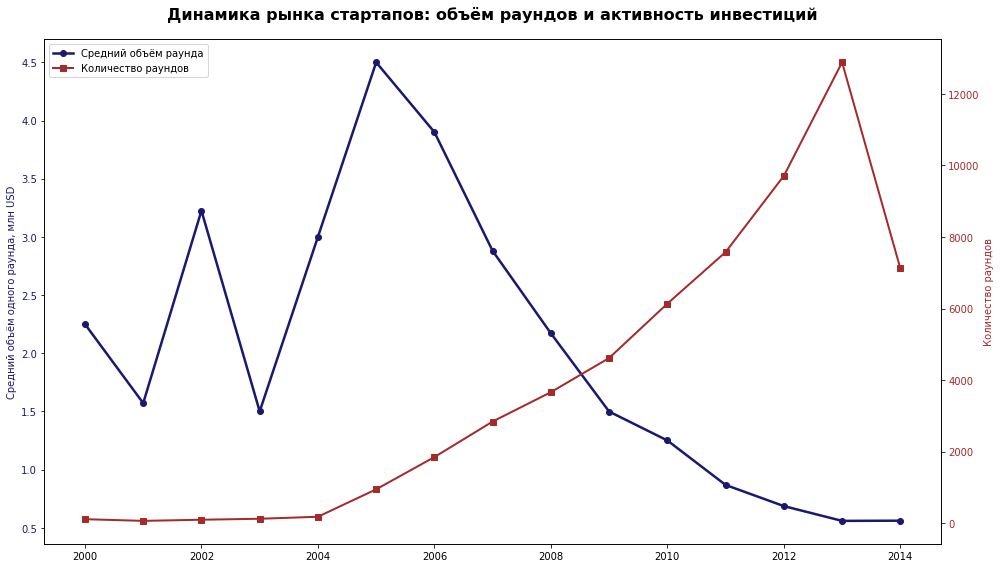

In [48]:

# Выделяем сумму и медиану
avg_round_year = df_investments.groupby('mid_year')['avg_usd'].median()
total_rounds_year = df_investments.groupby('mid_year')['funding_rounds'].sum()

# Создаём график
plt.figure(figsize=(14, 8))

# График среднего объёма раунда 
ax1 = plt.gca()  
line1 = ax1.plot(
    avg_round_year.index,
    avg_round_year.values / 1e6, 
    marker='o',
    linewidth=2.5,
    color='midnightblue',
    label='Средний объём раунда'
)
ax1.set_ylabel('Средний объём одного раунда, млн USD', color='midnightblue')
ax1.tick_params(axis='y', labelcolor='midnightblue')  

# Вторая ось Y для количества раундов
ax2 = ax1.twinx()
line2 = ax2.plot(
    total_rounds_year.index,
    total_rounds_year.values,
    marker='s',  
    linewidth=2.0,
    color='brown',
    label='Количество раундов'
)
ax2.set_ylabel('Количество раундов', color='brown')
ax2.tick_params(axis='y', labelcolor='brown')  

# Объединяем легенды
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

# Общие настройки графика
plt.title('Динамика рынка стартапов: объём раундов и активность инвестиций', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Год', fontsize=12)
plt.grid(True, axis='x', alpha=0.3)  

plt.tight_layout()
plt.show()


- Максимальное среднее значение одного раунда было достигнуто к концу 2005 года, и составило 4.5 млн., затем резко пошло на спад до антирекорда.  
- Количество раундов продолжало расти до 2013 года и затем также резко обвалилось

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

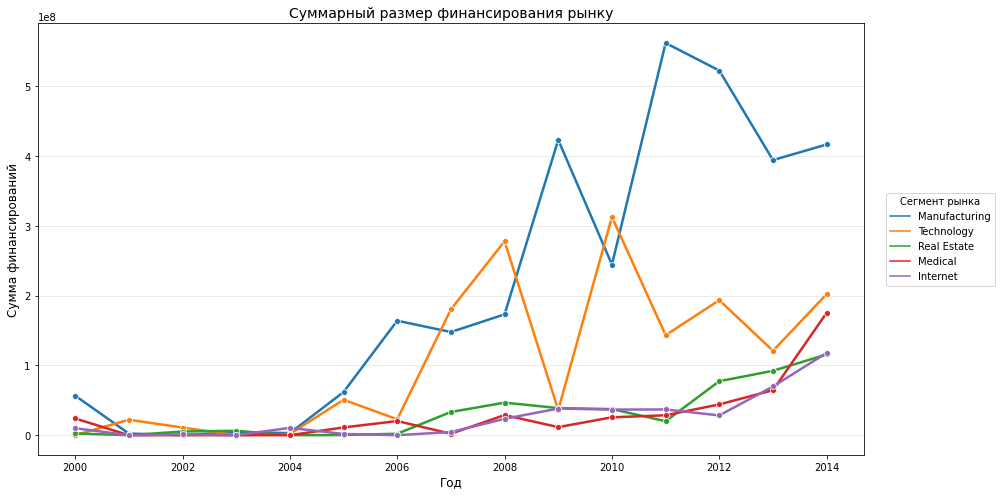

In [49]:


# Фильтруем данные за период 2000–2014 и исключаем сегменты с "mid" и "niche"
filtered_data = df_investments[
    (df_investments['mid_year'] >= 2000) &
    (df_investments['mid_year'] <= 2014) &
    (~df_investments['market'].str.contains('mid|niche', case=False, na=False)) &
    (df_investments['market'] != 'не указано')  # исключаем сегмент "не указано"
]

# Группируем по году и рынку, суммируем финансирование
yearly_funding = filtered_data.groupby(['mid_year', 'market'])['funding_total_usd'].sum().reset_index()

pivot_alt = yearly_funding.pivot(index='mid_year', columns='market', values='funding_total_usd').fillna(0)

# Считаем рост между 2014 и 2013 годами
growth_2014 = pivot_alt.loc[2014] - pivot_alt.loc[2013]

# Отбираем сегменты с положительным ростом
growing_segments = growth_2014[growth_2014 > 0].index

# Берём 5 сегментов с наибольшим суммарным финансированием за оба года
total_funding_by_segment = pivot_alt.sum().loc[growing_segments]
top_segments = total_funding_by_segment.sort_values(ascending=False).head(5).index

# Фильтруем таблицу, оставляя только топ‑5 сегментов
pivot_top_segments = pivot_alt[top_segments]


plt.figure(figsize=(14, 7))
sns.lineplot(
    data=pivot_top_segments.reset_index().melt(id_vars='mid_year', value_vars=top_segments),
    x='mid_year',
    y='value',
    hue='market',
    marker='o',
    linewidth=2.5
)

plt.title('Суммарный размер финансирования рынку', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Сумма финансирований', fontsize=12)
plt.legend(title='Сегмент рынка', bbox_to_anchor=(1.02, 0.5), loc='center left')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Manufacturing  превосходит все сегменты по сумме финансирования. Однако, хоть динамика роста имеется, сумма колеблется от года к году(хотя и показывает общий рост)
Technology сильно штормит и показывает порой резкие упадки до почти минимальных значений. Можно предположить, больше зависима от внешних факторов таких как медиа и т.д.
Internet, Real Estate, Medical показывают более спокойный, стабильный рост к 2014 году, с минимальными перепадами графика и с меньшими рисками.


### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

In [77]:

#  Группируем инвестиции по годам
invested_by_year = df_investments.groupby('last_year')[funding_types].sum()

# Берём данные по возвратам
returns_by_year = df_returns[funding_types] * 1000000

# Создаём полный диапазон лет (объединяем индексы из обоих датасетов)
all_years = pd.Index(sorted(set(invested_by_year.index) | set(returns_by_year.index)))

# Выравниваем оба датасета на полный диапазон лет с fill_value=0
invested_aligned = invested_by_year.reindex(all_years, fill_value=0)
returns_aligned = returns_by_year.reindex(all_years, fill_value=0)

# Рассчитываем коэффициент возврата в % с защитой от деления на ноль
epsilon = 1e-60
return_ratio = (returns_aligned / (invested_aligned + epsilon)) * 100

#  Функция очистки от выбросов методом IQR
def clean_outliers_iqr(df, multiplier=3):
    df_clean = df.copy()
    for col in df.columns:
        # Квартили
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        # Межквартильный размах и верхний порог
        IQR = Q3 - Q1
        upper_bound = Q3 + multiplier * IQR
        # Замена выбросов на NaN
        df_clean[col] = df_clean[col].where(df_clean[col] <= upper_bound, np.nan)
    return df_clean

# Применяем очистку
return_clean = clean_outliers_iqr(return_ratio)

return_clean


,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
2000.0,99.647118,16.892193,0.000000,69.704242,0.000000e+00,61.857143,26.695637,0.0,0.000000,2.710694e+01,0.000000,2.591054e+00,0.000000
2001.0,107.959178,10.799051,0.000000,58.748332,6.666667e-01,77.025782,118.000000,0.0,0.000000,4.600000e+67,0.000000,4.600000e+67,0.000000
2002.0,62.970655,68.228180,0.000000,60.887827,2.000000e+66,22.338821,113.666667,0.0,20.133333,1.133333e+02,0.000000,6.000000e+66,0.000000
2003.0,50.527619,62.826000,0.000000,91.439689,1.000000e+66,103.809524,60.572031,0.0,NaN,NaN,0.000000,8.000000e+66,0.000000
2004.0,54.847551,83.700914,0.000000,52.755930,1.000000e+66,43.969776,83.350426,0.0,NaN,NaN,0.000000,5.500000e+67,0.000000
2005.0,67.469541,54.658588,0.000000,107.199235,2.000000e+66,34.496435,50.989400,0.0,48.000000,7.318565e+01,0.000000,5.000000e+66,0.000000
2006.0,92.537180,34.367765,20.363172,75.943816,1.663181e+01,80.377203,67.485297,0.0,93.545296,NaN,0.000000,1.200000e+67,0.000000
2007.0,36.615335,29.724281,NaN,50.497081,2.280972e+01,60.248808,81.783745,0.0,57.905632,2.030000e+02,0.000000,5.700000e+67,0.000000
2008.0,29.708312,19.087260,NaN,34.206041,5.978832e+00,92.748376,41.247557,0.0,67.992540,2.341111e+02,0.000000,4.700000e+67,0.000000
2009.0,56.342259,16.951738,8.781897,37.617657,5.453492e+00,38.824855,61.594542,0.0,78.917095,2.095613e+02,0.000000,6.217617e-01,NaN


In [78]:
# Проверю коэффициэнт
# Статистика по инвестициям
print("Статистика инвестиций:")
print(invested_by_year.describe())

# Статистика по возвратам
print("\nСтатистика возвратов (до умножения):")
print(returns_by_year.describe())  # returns_by_year — это df_returns[funding_types]

# После применения коэффициента
print("\nСтатистика возвратов (после умножения на коэффициент):")
returns_scaled = returns_by_year * 1000000  
print(returns_scaled.describe())


Статистика инвестиций:
               seed       venture  equity_crowdfunding   undisclosed  \
count  1.500000e+01  1.500000e+01         1.500000e+01  1.500000e+01   
mean   6.287555e+08  8.606147e+09         1.586404e+07  1.400235e+08   
std    9.319035e+08  6.771449e+09         4.247101e+07  1.250945e+08   
min    2.667675e+06  2.175191e+08         0.000000e+00  8.871332e+06   
25%    1.743193e+07  5.181924e+08         0.000000e+00  5.193461e+07   
50%    1.922965e+08  9.256543e+09         0.000000e+00  1.096499e+08   
75%    8.351811e+08  1.486289e+10         5.245842e+06  2.076587e+08   
max    2.994848e+09  1.659551e+10         1.630343e+08  4.499645e+08   

       convertible_note  debt_financing         angel         grant  \
count      1.500000e+01    1.500000e+01  1.500000e+01  1.500000e+01   
mean       3.773596e+07    5.452102e+08  1.654176e+08  1.319232e+08   
std        4.599052e+07    5.994123e+08  1.533440e+08  1.796583e+08   
min        0.000000e+00    1.050000e+06  1.0

Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

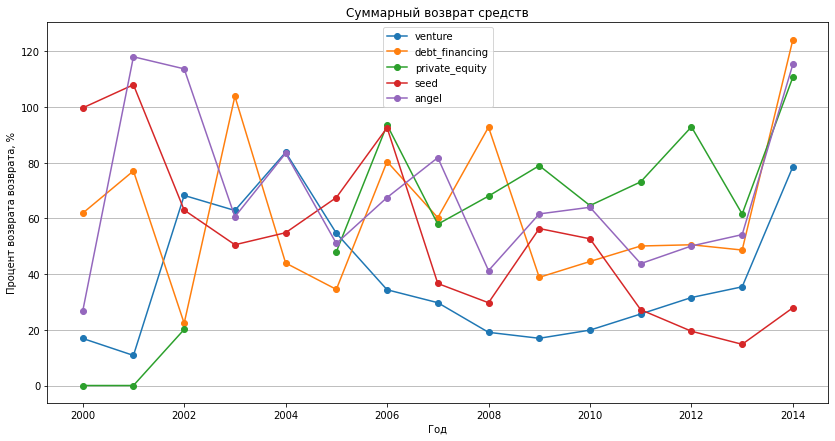

In [79]:
selected_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

df_plot = return_clean[selected_types]

plt.figure(figsize=(14,7))

for col in df_plot.columns:
    plt.plot(df_plot.index,
             df_plot[col], 
             marker='o',
             label=col)

plt.title('Суммарный возврат средств')
plt.xlabel('Год')
plt.ylabel('Процент возврата возврата, %')
plt.grid(True, axis='y')
plt.legend()
plt.show()

Наиболее стабильным типом оказался venture, не имеющий резких перепадов, но и не показывающий рост, и angel,  тогда как в остальных типах процент колеблется и не показывает стабильности.  
У private_equity и debt_financing напротив наблюдается экстремальные скачки
Хотя после 2009г. экстремальные разбросы спадают и типы примерно выравниваются, принимая похожие значения


## Шаг 5. Итоговый вывод и рекомендации

В ходе проекта был проведён полный цикл анализа данных:

- Провели предобработку данных:  
   - очищены дубликаты,  
   - обработаны пропущенные значения,  
   - изменены типы данных на более подходящие,  
   - удалены полностью пустых строки   

- Выделены три группы - с единичным финансированием, со сроком до года и более года.
- Классифицированы сегменты на нишевые (<35 компаний), средние (35–120) и массовые (>120). 
- Проанализированы выбросы методом IQR для каждого сегмента, выявлены сегментов с наибольшей долей аномального финансирования и составлены топы.
- Сравнена популярность и объём типов инвестиций.
- Расчитаны доли возврата средств по типам финансирования
- Исследованы изменения объёмов и количества раундов по годам, проанализированы динамики в массовых сегментах.

Выводы и рекомендации:

- Большинство компаний проходят один раунд финансирования; однако объём инвестиций приходится на них неравномерно и составляет меньшую долю общего объёма.
- Часть компаний привлекает долгосрочное финансирование, что обеспечивает подавляющую часть общего объёма инвестиций.
- Группа компаний с коротким сроком финансирования получает меньшую долю инвестиций.
Вывод: крупные суммы чаще идут в проекты с длительным горизонтом, даже если таких проектов меньшинство по числу.  



- Преобладают нишевые сегменты, но основной объём инвестиций сосредоточен в массовых направлениях.
- Нишевые сектора представляют возможности для целевых вложений с меньшей конкуренцией.
- Массовые направления вносят основную долю капитала, тогда как нишевые позволяют точечные вложения.  


- Венчурное финансирование лидирует по большинству параметров: востребованность, объём инвестиций и возвращаемость.
- Ранние стадии (seed/angel) работают как «рабочие лошадки» — инвестиции и доходность умеренно-низкая, но стабильная.
- Капитал в виде частной доли и долговые инструменты встречаются редко, но могут давать крупные входы и высокие потенциальные прибыли.  


Динамика и структура рынка

- Пик активности по числу раундов пройден, после чего наблюдается стабильное снижение.
- Сектора с технологиями демонстрируют наибольшую волатильность, в то же время остаются лидерами по объёмам и активности.
- Другие массовые сегменты показывают устойчивый рост с течением времени.
- В целом конвергенция подтверждает: концентрация капитала наиболее заметна в долгосрочных проектах и венчурном финансировании, а массовые сегменты остаются основными источниками инвестиций.  
- Вклад венчурного финансирования составляет значительную часть совокупной отдачи.
- Другие инструменты способны давать более переменчивую доходность, иногда превосходящую средний уровень, но с большим риском.
- Ранние стадии сохраняют стабильность в долгосрочной перспективе, тогда как крупные вложения в менее ликвидные типы обладают более высоким диапазоном возвратов.  


Рекомендации заказчику

- На первом месте в качестве направления — технологический сектор, поскольку он удерживает лидирующую долю инвестиций и отличается активностью, несмотря на нестабильность, однако желательно хорошо изучить проекты в этом сегменте до возможного финансирования.
- Альтернативно стоит рассмотреть крупные массовые сегменты с высоким потенциалом, но потребовать более тщательного отбора из‑за большей конкуренции и риска.
- Оптимальный тип финансирования для технологического блока — венчурное финансирование, обеспечивающее основную часть возвратов и объёмов капитала.
- В качестве резервного варианта для мониторинга — сегменты с высокой долей крупных проектов и потенциалом сверхдоходности, но без чрезмерного риска разброса.
Рекомендуемая стратегия: сосредоточиться на венчурных инвестициях в технологическом секторе, сохраняя баланс с мониторингом альтернативных массовых сегментов и управляемыми рисками - для сверхдоходности.  

